In [1]:
# ===========================================
# Customer Churn Prediction in Somaliland’s Telecommunications Sector Using Machine Learning
#: A Comparative Analysis of Classification Algorithms.
# ===========================================

#=================================
  #Import libraries
#=================================

# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
#=======================
  #Upload dataset
#=======================

from google.colab import files

uploaded = files.upload()

Saving telecom_customer_churn_5000_unique.csv to telecom_customer_churn_5000_unique.csv


In [3]:
#=================================
   #Load Datset
#==================================
df = pd.read_csv("telecom_customer_churn_5000_unique.csv")

In [4]:
#=============================
  #Display Dataset
#============================
df.head()

,CustomerID,Age,Gender,TenureMonths,MonthlyCharges,TotalCharges,InternetService,ContractType,DataUsageGB,CallMinutes,Complaints,PaymentMethod,Churn
0,502,31,Female,51,20.89,1065.39,NaN,Monthly,84.1,444,1,Card,0
1,587,23,Female,59,92.43,5453.37,Mobile,Monthly,37.5,1602,2,MobileMoney,1
2,654,58,Female,25,42.88,1072.00,NaN,Monthly,9.4,2641,3,Card,0
3,56,42,Female,3,104.24,312.72,Fiber,Two-Year,94.3,1273,6,Card,1
4,706,66,Male,23,71.14,1636.22,DSL,Two-Year,19.4,1613,5,Bank,0


In [5]:
#============================
 #Dataset Shape
#=============================
print("Rows and Columns:", df.shape)

Rows and Columns: (5000, 13)


In [6]:
#=============================
  #Columns
#=============================
df.columns

Index(['CustomerID', 'Age', 'Gender', 'TenureMonths', 'MonthlyCharges',
       'TotalCharges', 'InternetService', 'ContractType', 'DataUsageGB',
       'CallMinutes', 'Complaints', 'PaymentMethod', 'Churn'],
      dtype='object')

In [7]:
#====================================
  #Data Types
#====================================
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       5000 non-null   int64  
 1   Age              5000 non-null   int64  
 2   Gender           5000 non-null   object 
 3   TenureMonths     5000 non-null   int64  
 4   MonthlyCharges   5000 non-null   float64
 5   TotalCharges     5000 non-null   float64
 6   InternetService  3733 non-null   object 
 7   ContractType     5000 non-null   object 
 8   DataUsageGB      5000 non-null   float64
 9   CallMinutes      5000 non-null   int64  
 10  Complaints       5000 non-null   int64  
 11  PaymentMethod    5000 non-null   object 
 12  Churn            5000 non-null   int64  
dtypes: float64(3), int64(6), object(4)
memory usage: 507.9+ KB


In [8]:
#========================================
 #Statitical Summmarey
#========================================
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,5000.0,2500.500000,1443.520003,1.00,1250.750,2500.500,3750.250,5000.00
Age,5000.0,44.548200,15.236775,18.00,31.000,45.000,57.000,73.00
TenureMonths,5000.0,36.776800,20.704722,0.00,18.000,37.000,55.000,72.00
MonthlyCharges,5000.0,63.530224,32.111862,9.72,35.925,62.455,90.695,125.05
TotalCharges,5000.0,2342.384738,1891.947281,0.00,761.145,1757.120,3582.530,9003.60
DataUsageGB,5000.0,50.076522,28.345142,1.00,26.000,49.785,72.945,120.76
CallMinutes,5000.0,1560.682600,859.857503,22.00,801.000,1572.000,2328.250,3028.00
Complaints,5000.0,3.127800,2.051806,0.00,1.000,3.000,5.000,7.00
Churn,5000.0,0.242000,0.428337,0.00,0.000,0.000,0.000,1.00


In [9]:
#===============================
  #check missing values
#================================
df.isnull().sum()

,0
CustomerID,0
Age,0
Gender,0
TenureMonths,0
MonthlyCharges,0
TotalCharges,0
InternetService,1267
ContractType,0
DataUsageGB,0
CallMinutes,0


In [10]:
#==================================================
 #Fill missing values in InternetService
#===================================================
df["InternetService"] = df["InternetService"].fillna("Unknown")

In [11]:
#===============================
  #check missing values
#================================
df.isnull().sum()

,0
CustomerID,0
Age,0
Gender,0
TenureMonths,0
MonthlyCharges,0
TotalCharges,0
InternetService,0
ContractType,0
DataUsageGB,0
CallMinutes,0


In [12]:
#============================
 #Duplicate check
#===========================
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 0


Churn
0    3790
1    1210
Name: count, dtype: int64


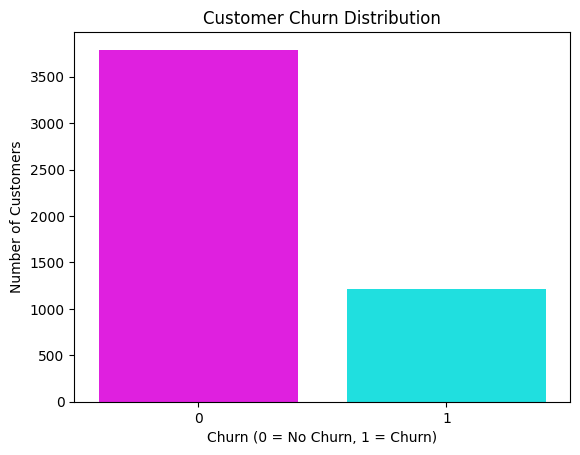

In [13]:

#==================================
 #visualization
#==================================

# Check target (Churn)
print(df['Churn'].value_counts())

# Create count plot
sns.countplot(
    x='Churn',
    data=df,
    palette={0: 'magenta', 1: 'cyan'},
    hue='Churn',
    legend=False
)

# Add title and labels
plt.title('Customer Churn Distribution')
plt.xlabel('Churn (0 = No Churn, 1 = Churn)')
plt.ylabel('Number of Customers')

# Display the plot
plt.show()





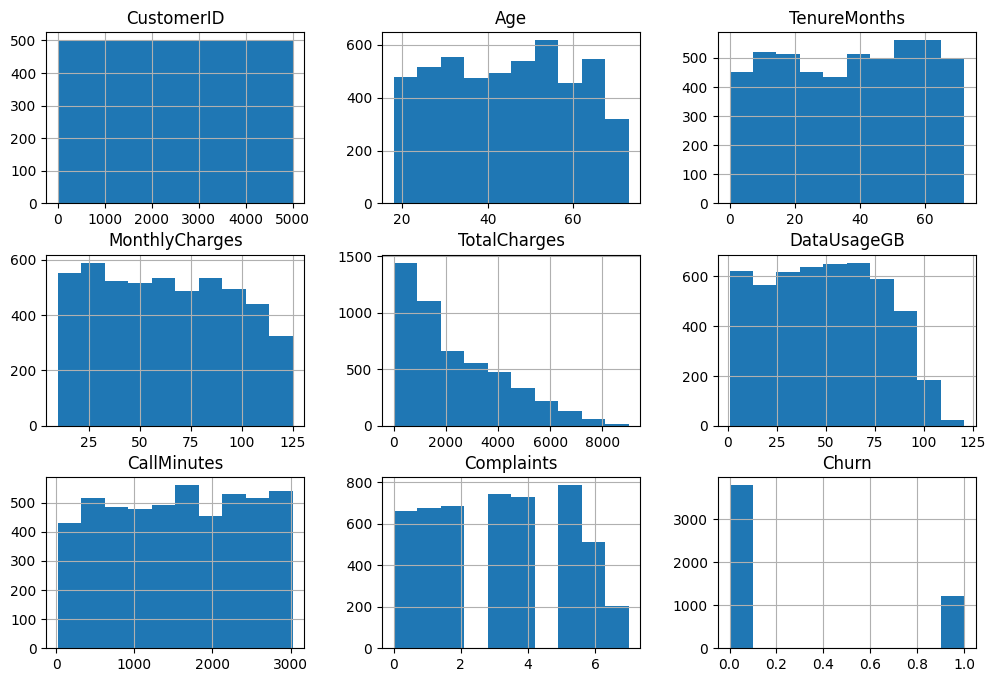

In [14]:
#=======================================
 #Numerical features distribution
#=======================================
df.hist(figsize=(12,8))
plt.show()

In [15]:
#===================================
 #Remove ID
#=====================================
df = df.drop(columns=['CustomerID'])

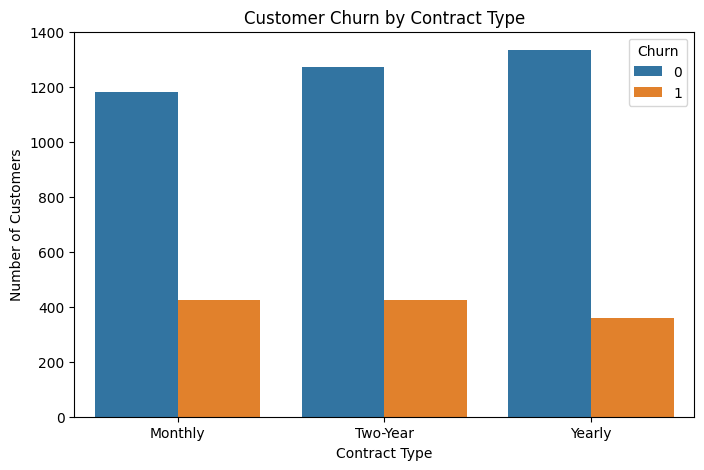

In [16]:
#============================
 #A.Churn by Contract
#=============================

plt.figure(figsize=(8,5))

sns.countplot(
    x='ContractType',
    hue='Churn',
    data=df
)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

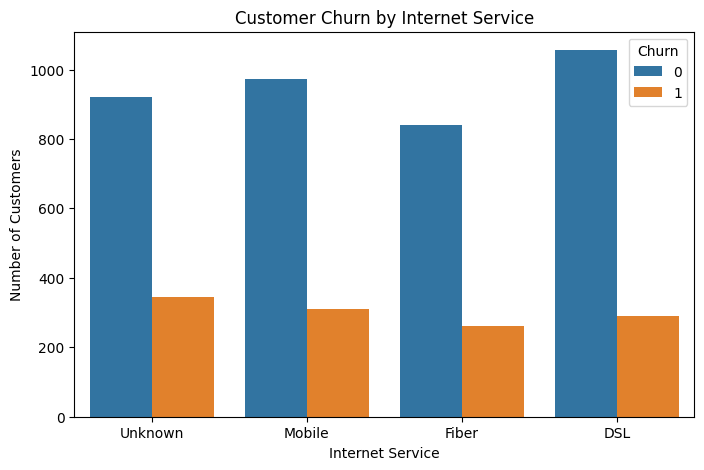

In [17]:
#=======================================
 #B.Churn by InternetServices
#=======================================
plt.figure(figsize=(8,5))

sns.countplot(
    x='InternetService',
    hue='Churn',
    data=df
)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')
plt.show()

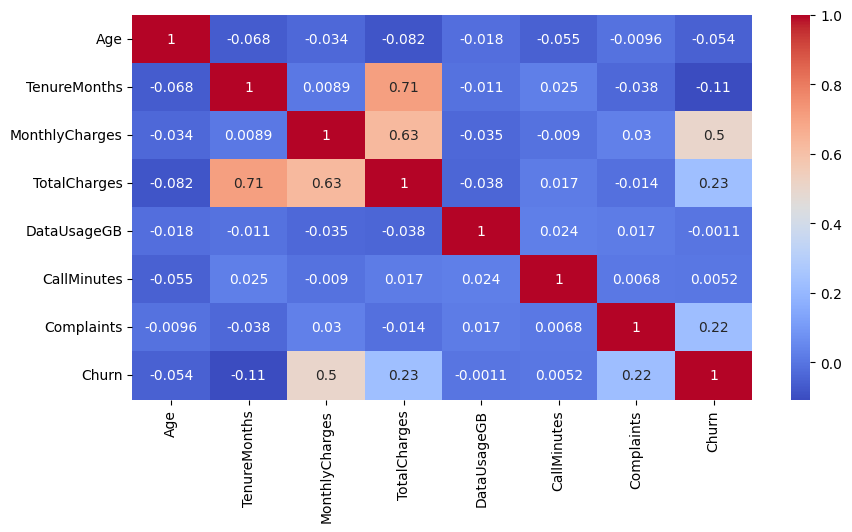

In [18]:
#=========================
 #Correlation
#========================
plt.figure(figsize=(10,5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

In [19]:
#================================
 #Encode categorical variables
#=================================
df_encoded = pd.get_dummies(df, drop_first=True)

In [20]:
X = df_encoded.drop('Churn', axis=1)
y = df_encoded['Churn']

In [21]:
#=============================================
 #train and test split
#=============================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [22]:
#=====================================
 #Baseline model
#======================================
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [23]:
#======================================
 #Evaluation
#======================================


print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.86
              precision    recall  f1-score   support

           0       0.88      0.94      0.91       758
           1       0.76      0.61      0.68       242

    accuracy                           0.86      1000
   macro avg       0.82      0.78      0.79      1000
weighted avg       0.85      0.86      0.85      1000



In [24]:
#====================================
# Decision Tree
#====================================

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

In [25]:
#=====================================
 #Evaluation
#=====================================

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.892
              precision    recall  f1-score   support

           0       0.92      0.93      0.93       758
           1       0.79      0.76      0.77       242

    accuracy                           0.89      1000
   macro avg       0.86      0.85      0.85      1000
weighted avg       0.89      0.89      0.89      1000



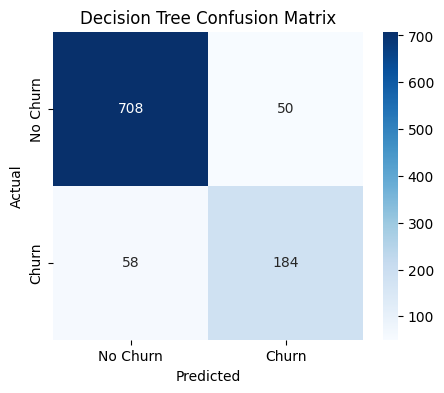

In [26]:
#===============================
 #Confusion Matrix
#=============================

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(5,4))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['No Churn','Churn'],
            yticklabels=['No Churn','Churn'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [27]:
#====================================
# Random Forest Classifier
#====================================
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [28]:
#===================================
 #Evaluation
#===================================
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.95
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       758
           1       0.94      0.84      0.89       242

    accuracy                           0.95      1000
   macro avg       0.95      0.91      0.93      1000
weighted avg       0.95      0.95      0.95      1000



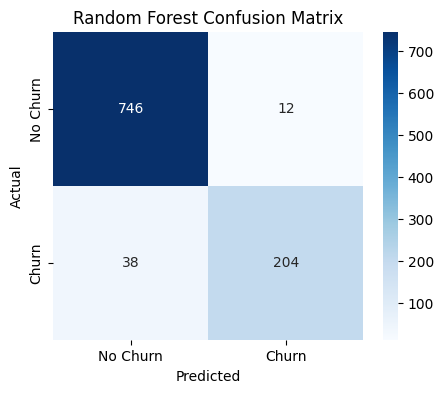

In [29]:
#=================================
 #Confusion Matrix
#=================================
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(5,4))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['No Churn','Churn'],
            yticklabels=['No Churn','Churn'])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [30]:
#===============================

 #import xgboost
#================================

import xgboost
print(xgboost.__version__)

3.4.1


In [31]:
#====================================
# XGBoost Classifier
#====================================

from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

In [32]:
#==============================
 #Evaluation
#==============================

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))

Accuracy: 0.943
              precision    recall  f1-score   support

           0       0.95      0.98      0.96       758
           1       0.93      0.82      0.87       242

    accuracy                           0.94      1000
   macro avg       0.94      0.90      0.92      1000
weighted avg       0.94      0.94      0.94      1000



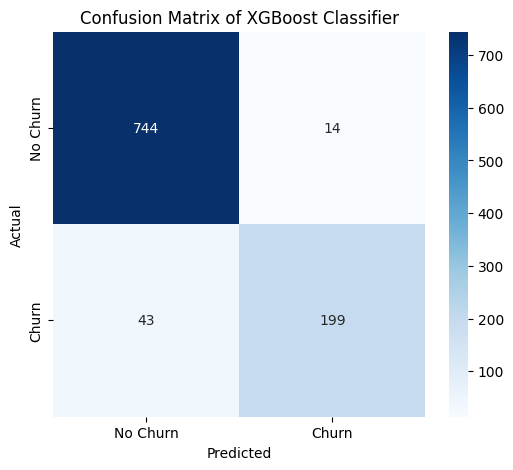

In [33]:
#====================================
# XGBoost Confusion Matrix
#====================================


cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix of XGBoost Classifier")
plt.show()

========== AUC Scores ==========
Logistic Regression : 0.8802
Decision Tree       : 0.8472
Random Forest       : 0.9260
XGBoost             : 0.9255


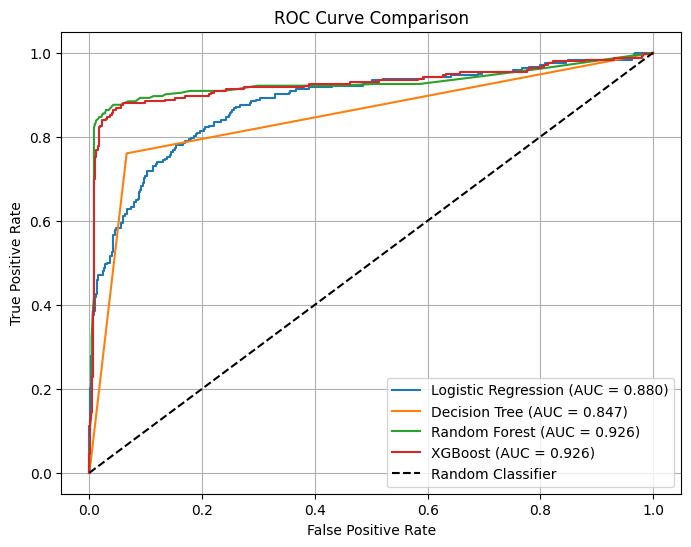

In [34]:
#=========================================
# ROC Curve and AUC Score
#=========================================

from sklearn.metrics import roc_curve, roc_auc_score


# Predict probabilities for Churn class (1)
lr_probs = model.predict_proba(X_test)[:, 1]
dt_probs = dt_model.predict_proba(X_test)[:, 1]
rf_probs = rf_model.predict_proba(X_test)[:, 1]
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

# Calculate ROC curves
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)
dt_fpr, dt_tpr, _ = roc_curve(y_test, dt_probs)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)

# Calculate AUC scores
lr_auc = roc_auc_score(y_test, lr_probs)
dt_auc = roc_auc_score(y_test, dt_probs)
rf_auc = roc_auc_score(y_test, rf_probs)
xgb_auc = roc_auc_score(y_test, xgb_probs)

# Print AUC scores
print("========== AUC Scores ==========")
print(f"Logistic Regression : {lr_auc:.4f}")
print(f"Decision Tree       : {dt_auc:.4f}")
print(f"Random Forest       : {rf_auc:.4f}")
print(f"XGBoost             : {xgb_auc:.4f}")

# Plot ROC curves
plt.figure(figsize=(8,6))

plt.plot(
    lr_fpr, lr_tpr,
    label=f'Logistic Regression (AUC = {lr_auc:.3f})'
)

plt.plot(
    dt_fpr, dt_tpr,
    label=f'Decision Tree (AUC = {dt_auc:.3f})'
)

plt.plot(
    rf_fpr, rf_tpr,
    label=f'Random Forest (AUC = {rf_auc:.3f})'
)

plt.plot(
    xgb_fpr, xgb_tpr,
    label=f'XGBoost (AUC = {xgb_auc:.3f})'
)

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    'k--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.grid(True)

plt.show()

In [35]:
#========================================================
  #(AUC + Accuracy + F1-score Table)
#=========================================================
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
import pandas as pd

# Accuracy
lr_acc = accuracy_score(y_test, model.predict(X_test))
dt_acc = accuracy_score(y_test, dt_model.predict(X_test))
rf_acc = accuracy_score(y_test, rf_model.predict(X_test))
xgb_acc = accuracy_score(y_test, xgb_model.predict(X_test))

# F1-score
lr_f1 = f1_score(y_test, model.predict(X_test))
dt_f1 = f1_score(y_test, dt_model.predict(X_test))
rf_f1 = f1_score(y_test, rf_model.predict(X_test))
xgb_f1 = f1_score(y_test, xgb_model.predict(X_test))

# AUC (using probabilities)
lr_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
dt_auc = roc_auc_score(y_test, dt_model.predict_proba(X_test)[:,1])
rf_auc = roc_auc_score(y_test, rf_model.predict_proba(X_test)[:,1])
xgb_auc = roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:,1])

# Create DataFrame
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"],
    "Accuracy": [lr_acc, dt_acc, rf_acc, xgb_acc],
    "F1-Score": [lr_f1, dt_f1, rf_f1, xgb_f1],
    "AUC Score": [lr_auc, dt_auc, rf_auc, xgb_auc]
})

# Round for thesis presentation
results = results.round(4)

results

,Model,Accuracy,F1-Score,AUC Score
0,Logistic Regression,0.860,0.6789,0.8802
1,Decision Tree,0.892,0.7731,0.8472
2,Random Forest,0.950,0.8908,0.9260
3,XGBoost,0.943,0.8747,0.9255


In [36]:
#=======================================
 #Model Comparison
#======================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": y_pred_dt,
    "Randomforest":y_pred_rf,
    "XGBoost": y_pred_xgb
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred)
    })

df_results = pd.DataFrame(results)
df_results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.860,0.762887,0.611570,0.678899
1,Decision Tree,0.892,0.786325,0.760331,0.773109
2,Randomforest,0.950,0.944444,0.842975,0.890830
3,XGBoost,0.943,0.934272,0.822314,0.874725


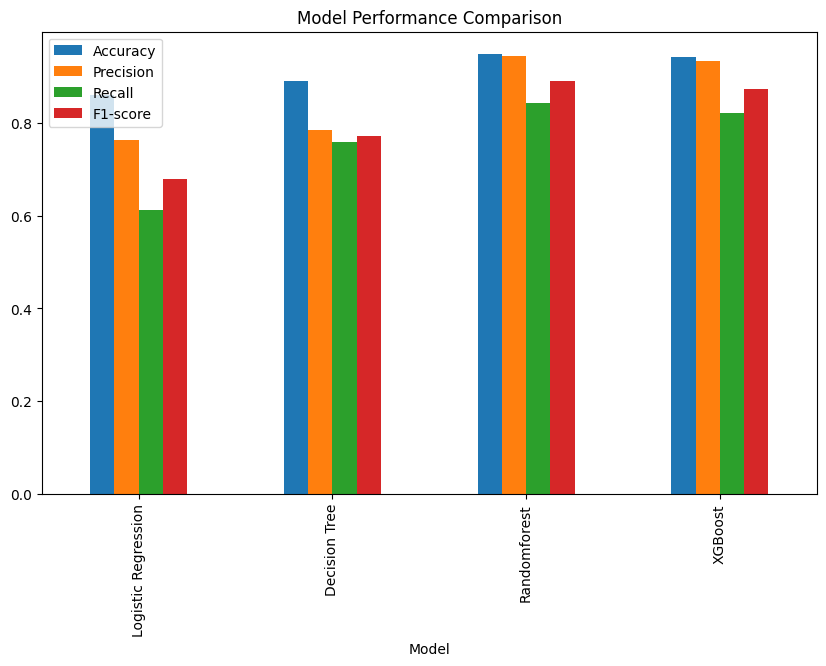

In [37]:
#===========================================
  #Visual Comparison
#===========================================

df_results.set_index("Model")[["Accuracy","Precision","Recall","F1-score"]].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Model Performance Comparison")
plt.show()

In [38]:
#=============================
 #10 Ten features
#===========================
importance = pd.Series(
    xgb_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.head(10)

,0
MonthlyCharges,0.204690
Complaints,0.150139
ContractType_Yearly,0.142800
ContractType_Two-Year,0.083051
InternetService_Mobile,0.047485
TenureMonths,0.046991
Gender_Male,0.044675
InternetService_Unknown,0.037594
PaymentMethod_Card,0.036201
PaymentMethod_Cash,0.035447


In [39]:
# =====================================
# Feature Importance - Top 10 Features
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Select Top 10 features
top_10 = feature_importance.head(10)

# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features for Customer Churn Prediction')
plt.xlabel('Importance Score')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

AttributeError: 'LogisticRegression' object has no attribute 'feature_importances_'

In [ ]:
#=========================================
# Final Model Selection
#=========================================

best_model = df_results.loc[
    df_results['F1-score'].idxmax()
]

print("Best Performing Model:")
print(best_model)